# Enterprise Policy Copilot — Stage 5: Local Dense Embeddings and FAISS Vector Indexing

## 1. Introduction and Objectives
In this stage of the **Enterprise Policy Copilot** project, we construct a fully local, reproducible dense embedding and vector-indexing pipeline using:
- **Sentence Transformers** (`all-MiniLM-L6-v2` and `all-mpnet-base-v2`) for local dense representation.
- **FAISS (Facebook AI Similarity Search)** with `IndexFlatIP` and **L2-normalized embeddings** for exact cosine similarity nearest-neighbor retrieval.

### Security and Data Privacy Rules
1. **Synthetic Data Exclusively**: Only fictional policies loaded from `data/sample/synthetic_policies.json`.
2. **Local Inference Only**: All model inference and vector indexing occur on the local CPU runtime.
3. **Zero Data Transmission**: Zero calls to hosted embedding APIs (e.g. OpenAI, Cohere) or cloud vector databases (e.g. Supabase, Pinecone).
4. **Reproducible Pipeline**: All six combinations of 3 chunking strategies × 2 embedding models are built and indexed independently.


## 2. Load Synthetic Policy Dataset
We load the validated 15 synthetic policy sections across 3 policy documents from `data/sample/synthetic_policies.json`.


In [1]:
import sys
import json
import os
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
current_dir = Path.cwd()
project_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.retrieval.chunking import (
    chunk_policy_dataset,
    chunk_policy_dataset_section_aware,
    chunk_policy_dataset_sentence_window,
)
from src.retrieval.embeddings import (
    load_embedding_model,
    get_embedding_dimension,
    embed_chunks,
    embed_texts,
    normalize_embeddings,
)
from src.retrieval.vector_store import (
    FAISSVectorStore,
    create_vector_store,
)

# Load dataset
data_path = project_root / "data" / "sample" / "synthetic_policies.json"
print(f"Loading synthetic policies from: {data_path}")
with open(data_path, "r", encoding="utf-8") as f:
    policies_data = json.load(f)

# Handle both flat list of section dicts and nested dict {"policies": [...]}
if isinstance(policies_data, dict) and "policies" in policies_data:
    policies = policies_data["policies"]
elif isinstance(policies_data, list):
    policies = policies_data
else:
    raise ValueError(f"Unexpected data format in {data_path}")

print(f"Successfully loaded {len(policies)} policy sections!")
unique_docs = sorted(list(set(p.get("doc_id", "Unknown") for p in policies)))
print(f"Unique documents ({len(unique_docs)}): {unique_docs}")


Loading synthetic policies from: C:\Users\sandhiya\OneDrive\Data Science Intern\Enterprise-Policy-Copilot\data\sample\synthetic_policies.json
Successfully loaded 15 policy sections!
Unique documents (3): ['POL-AL-001', 'POL-LA-003', 'POL-SL-002']


## 3. Generate Chunks for All Three Chunking Strategies
We produce chunks across all 3 strategies using the established parameters from Stages 2, 3, and 4:
1. **Fixed-Size Chunking**: `chunk_size=500`, `chunk_overlap=100`
2. **Section-Aware Chunking**: `chunk_size=500`, `chunk_overlap=100`
3. **Sentence-Window Chunking**: `window_size=3`, `step_size=1`


In [2]:
# 1. Fixed-size chunks
chunks_fixed = chunk_policy_dataset(policies, chunk_size=500, chunk_overlap=100)

# 2. Section-aware chunks
chunks_section = chunk_policy_dataset_section_aware(policies, chunk_size=500, chunk_overlap=100)

# 3. Sentence-window chunks
chunks_window = chunk_policy_dataset_sentence_window(policies, window_size=3, step_size=1)

print(f"Strategy 1 (Fixed-Size):      {len(chunks_fixed)} chunks")
print(f"Strategy 2 (Section-Aware):   {len(chunks_section)} chunks")
print(f"Strategy 3 (Sentence-Window): {len(chunks_window)} chunks")


Strategy 1 (Fixed-Size):      30 chunks
Strategy 2 (Section-Aware):   40 chunks
Strategy 3 (Sentence-Window): 46 chunks


## 4. Load and Compare Embedding Models
We load two local Sentence Transformers models:
1. `sentence-transformers/all-MiniLM-L6-v2` (fast, lightweight, 384 dimensions)
2. `sentence-transformers/all-mpnet-base-v2` (high-capacity transformer, 768 dimensions)

Both models are verified programmatically without hardcoded dimensions.


In [3]:
print("Loading Model 1: sentence-transformers/all-MiniLM-L6-v2 ...")
t0 = time.perf_counter()
model_minilm = load_embedding_model("sentence-transformers/all-MiniLM-L6-v2")
t_minilm_load = time.perf_counter() - t0
dim_minilm = get_embedding_dimension(model_minilm)

print(f"Model 1 loaded in {t_minilm_load:.2f}s | Programmatic Dimension: {dim_minilm}")

print("\nLoading Model 2: sentence-transformers/all-mpnet-base-v2 ...")
t0 = time.perf_counter()
model_mpnet = load_embedding_model("sentence-transformers/all-mpnet-base-v2")
t_mpnet_load = time.perf_counter() - t0
dim_mpnet = get_embedding_dimension(model_mpnet)

print(f"Model 2 loaded in {t_mpnet_load:.2f}s | Programmatic Dimension: {dim_mpnet}")

model_specs_df = pd.DataFrame([
    {
        "Model Name": "all-MiniLM-L6-v2",
        "Architecture": "BERT-based MiniLM (6 layers)",
        "Embedding Dimension": dim_minilm,
        "Load Time (s)": round(t_minilm_load, 2),
        "Parameters": "~22.7M",
        "Default Max Seq Length": getattr(model_minilm, "max_seq_length", 256),
    },
    {
        "Model Name": "all-mpnet-base-v2",
        "Architecture": "MPNet-base (12 layers)",
        "Embedding Dimension": dim_mpnet,
        "Load Time (s)": round(t_mpnet_load, 2),
        "Parameters": "~109M",
        "Default Max Seq Length": getattr(model_mpnet, "max_seq_length", 384),
    }
])
display(model_specs_df)


Loading Model 1: sentence-transformers/all-MiniLM-L6-v2 ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model 1 loaded in 41.03s | Programmatic Dimension: 384

Loading Model 2: sentence-transformers/all-mpnet-base-v2 ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model 2 loaded in 4.91s | Programmatic Dimension: 768


,Model Name,Architecture,Embedding Dimension,Load Time (s),Parameters,Default Max Seq Length
0,all-MiniLM-L6-v2,BERT-based MiniLM (6 layers),384,41.03,~22.7M,256
1,all-mpnet-base-v2,MPNet-base (12 layers),768,4.91,~109M,384


## 5. Generate Local Embeddings for All Chunking Strategies
We embed all three chunk sets using both models, generating 6 independent embedding matrices.
All vectors are **L2-normalized** ($||v||_2 = 1.0$), ensuring that Inner Product computations directly equal Cosine Similarity:
$$\text{Cosine Similarity}(u, v) = \frac{u \cdot v}{||u||_2 ||v||_2} = u_{norm} \cdot v_{norm} = \text{Inner Product}(u_{norm}, v_{norm})$$


In [4]:
strategies = {
    "fixed_size": chunks_fixed,
    "section_aware": chunks_section,
    "sentence_window": chunks_window,
}

embedding_results = {}
timing_records = []

for strat_name, chunk_list in strategies.items():
    print(f"--- Embedding {strat_name} ({len(chunk_list)} chunks) ---")
    
    # MiniLM
    res_minilm = embed_chunks(chunk_list, model_minilm, batch_size=32, normalize=True)
    embedding_results[f"{strat_name}_minilm"] = res_minilm
    timing_records.append({
        "Strategy": strat_name,
        "Model": "all-MiniLM-L6-v2",
        "Num Chunks": len(chunk_list),
        "Embedding Dim": res_minilm["model_dim"],
        "Time (s)": round(res_minilm["elapsed_time"], 3),
        "Speed (chunks/s)": round(len(chunk_list) / res_minilm["elapsed_time"], 1) if res_minilm["elapsed_time"] > 0 else 0,
        "Matrix Shape": str(res_minilm["embeddings"].shape),
    })
    
    # MPNet
    res_mpnet = embed_chunks(chunk_list, model_mpnet, batch_size=32, normalize=True)
    embedding_results[f"{strat_name}_mpnet"] = res_mpnet
    timing_records.append({
        "Strategy": strat_name,
        "Model": "all-mpnet-base-v2",
        "Num Chunks": len(chunk_list),
        "Embedding Dim": res_mpnet["model_dim"],
        "Time (s)": round(res_mpnet["elapsed_time"], 3),
        "Speed (chunks/s)": round(len(chunk_list) / res_mpnet["elapsed_time"], 1) if res_mpnet["elapsed_time"] > 0 else 0,
        "Matrix Shape": str(res_mpnet["embeddings"].shape),
    })

timing_df = pd.DataFrame(timing_records)
print("\nEmbedding Performance Summary:")
display(timing_df)


--- Embedding fixed_size (30 chunks) ---


--- Embedding section_aware (40 chunks) ---


--- Embedding sentence_window (46 chunks) ---



Embedding Performance Summary:


,Strategy,Model,Num Chunks,Embedding Dim,Time (s),Speed (chunks/s),Matrix Shape
0,fixed_size,all-MiniLM-L6-v2,30,384,1.412,21.2,"(30, 384)"
1,fixed_size,all-mpnet-base-v2,30,768,8.883,3.4,"(30, 768)"
2,section_aware,all-MiniLM-L6-v2,40,384,1.588,25.2,"(40, 384)"
3,section_aware,all-mpnet-base-v2,40,768,10.684,3.7,"(40, 768)"
4,sentence_window,all-MiniLM-L6-v2,46,384,1.601,28.7,"(46, 384)"
5,sentence_window,all-mpnet-base-v2,46,768,12.398,3.7,"(46, 768)"


## 6. Build and Persist Six Independent FAISS Indexes
We create six distinct `FAISSVectorStore` instances using `IndexFlatIP`.
Each store preserves an explicit mapping between FAISS row positions and chunk metadata.
All indexes and their metadata sidecars are saved locally into `data/vector_store/synthetic/`.


In [5]:
output_dir = project_root / "data" / "vector_store" / "synthetic"
output_dir.mkdir(parents=True, exist_ok=True)

vector_stores = {}
index_metadata_summary = []

for key, emb_res in embedding_results.items():
    store = create_vector_store(
        embeddings=emb_res["embeddings"],
        metadata=emb_res["metadata"],
        chunk_ids=emb_res["chunk_ids"],
        dimension=emb_res["model_dim"],
        normalize=False, # already L2-normalized during embedding
    )
    vector_stores[key] = store
    
    # Save locally
    idx_path, meta_path = store.save(output_dir, prefix=key)
    
    idx_size_kb = os.path.getsize(idx_path) / 1024
    meta_size_kb = os.path.getsize(meta_path) / 1024
    
    index_metadata_summary.append({
        "Index Name": key,
        "Total Vectors": store.total_vectors,
        "Dimension": store.dimension,
        "Index Type": store.index_type,
        "FAISS File Size (KB)": round(idx_size_kb, 2),
        "Metadata Sidecar (KB)": round(meta_size_kb, 2),
    })

index_df = pd.DataFrame(index_metadata_summary)
display(index_df)


,Index Name,Total Vectors,Dimension,Index Type,FAISS File Size (KB),Metadata Sidecar (KB)
0,fixed_size_minilm,30,384,FlatIP,45.04,24.00
1,fixed_size_mpnet,30,768,FlatIP,90.04,24.00
2,section_aware_minilm,40,384,FlatIP,60.04,33.09
3,section_aware_mpnet,40,768,FlatIP,120.04,33.09
4,sentence_window_minilm,46,384,FlatIP,69.04,38.55
5,sentence_window_mpnet,46,768,FlatIP,138.04,38.55


## 7. Verify Local Deserialization (Save and Load)
We test loading one index back from disk to verify reproducibility and byte-level integrity.


In [6]:
test_key = "section_aware_minilm"
loaded_store = FAISSVectorStore.load(output_dir, prefix=test_key)

print(f"Successfully loaded '{test_key}' from disk!")
print(f" - Dimension:     {loaded_store.dimension}")
print(f" - Total Vectors: {loaded_store.total_vectors}")
print(f" - Metadata count: {len(loaded_store.metadata_store)}")
assert loaded_store.total_vectors == vector_stores[test_key].total_vectors
assert len(loaded_store.metadata_store) == len(vector_stores[test_key].metadata_store)
print("Integrity check passed: vector count and metadata match exactly.")


Successfully loaded 'section_aware_minilm' from disk!
 - Dimension:     384
 - Total Vectors: 40
 - Metadata count: 40
Integrity check passed: vector count and metadata match exactly.


## 8. Example Semantic Search with Synthetic Policy Questions
We query the 6 vector stores using 3 realistic, synthetic employee policy questions:
1. *"How many consecutive sick leave days require a medical certificate?"*
2. *"Can I carry forward unused annual leave to the next calendar year?"*
3. *"What is the notice period required before taking more than five days of leave?"*


In [7]:
synthetic_queries = [
    {
        "query_id": "Q1",
        "question": "How many consecutive sick leave days require a medical certificate?",
        "expected_topic": "Sick Leave Certification / Medical Certificate"
    },
    {
        "query_id": "Q2",
        "question": "Can I carry forward unused annual leave to the next calendar year?",
        "expected_topic": "Annual Leave Carry-Forward Rules"
    },
    {
        "query_id": "Q3",
        "question": "What is the notice period required before taking more than five days of leave?",
        "expected_topic": "Leave Request Notice Periods / Approval"
    }
]

search_results = []

for q_item in synthetic_queries:
    qid = q_item["query_id"]
    query_text = q_item["question"]
    
    # Embed query with MiniLM
    q_emb_minilm, _ = embed_texts([query_text], model_minilm, normalize=True)
    # Embed query with MPNet
    q_emb_mpnet, _ = embed_texts([query_text], model_mpnet, normalize=True)
    
    for key, store in vector_stores.items():
        q_emb = q_emb_minilm if "minilm" in key else q_emb_mpnet
        matches = store.search(q_emb, k=3, normalize_query=False) # already normalized
        
        top1 = matches[0] if matches else None
        if top1:
            search_results.append({
                "Query ID": qid,
                "Question": query_text,
                "Index Key": key,
                "Top-1 Chunk ID": top1["chunk_id"],
                "Top-1 Score": round(top1["score"], 4),
                "Document": top1["metadata"].get("document_title"),
                "Section": top1["metadata"].get("section_heading"),
                "Snippet": top1["metadata"].get("chunk_text", "")[:120] + "...",
            })

search_df = pd.DataFrame(search_results)
display(search_df[["Query ID", "Index Key", "Top-1 Score", "Document", "Section", "Snippet"]])


,Query ID,Index Key,Top-1 Score,Document,Section,Snippet
0,Q1,fixed_size_minilm,0.8020,Sick Leave Policy,Medical Documentation,A medical certificate from a registered medica...
1,Q1,fixed_size_mpnet,0.7974,Sick Leave Policy,Medical Documentation,A medical certificate from a registered medica...
2,Q1,section_aware_minilm,0.8150,Sick Leave Policy,Medical Documentation,A medical certificate from a registered medica...
3,Q1,section_aware_mpnet,0.8183,Sick Leave Policy,Medical Documentation,A medical certificate from a registered medica...
4,Q1,sentence_window_minilm,0.8150,Sick Leave Policy,Medical Documentation,A medical certificate from a registered medica...
5,Q1,sentence_window_mpnet,0.8183,Sick Leave Policy,Medical Documentation,A medical certificate from a registered medica...
6,Q2,fixed_size_minilm,0.6685,Annual Leave Policy,Leave Entitlement,-forward leave that is not used by this deadli...
7,Q2,fixed_size_mpnet,0.6777,Sick Leave Policy,Eligibility and Entitlement,do not carry forward to the next calendar year...
8,Q2,section_aware_minilm,0.6602,Annual Leave Policy,Leave Entitlement,Any unused carried-forward leave that is not u...
9,Q2,section_aware_mpnet,0.6820,Annual Leave Policy,Leave Entitlement,Any unused carried-forward leave that is not u...


## 9. Comparative Visualization: Retrieval Scores Across Configurations
We visualize the Top-1 cosine similarity scores across queries, chunking strategies, and embedding models.


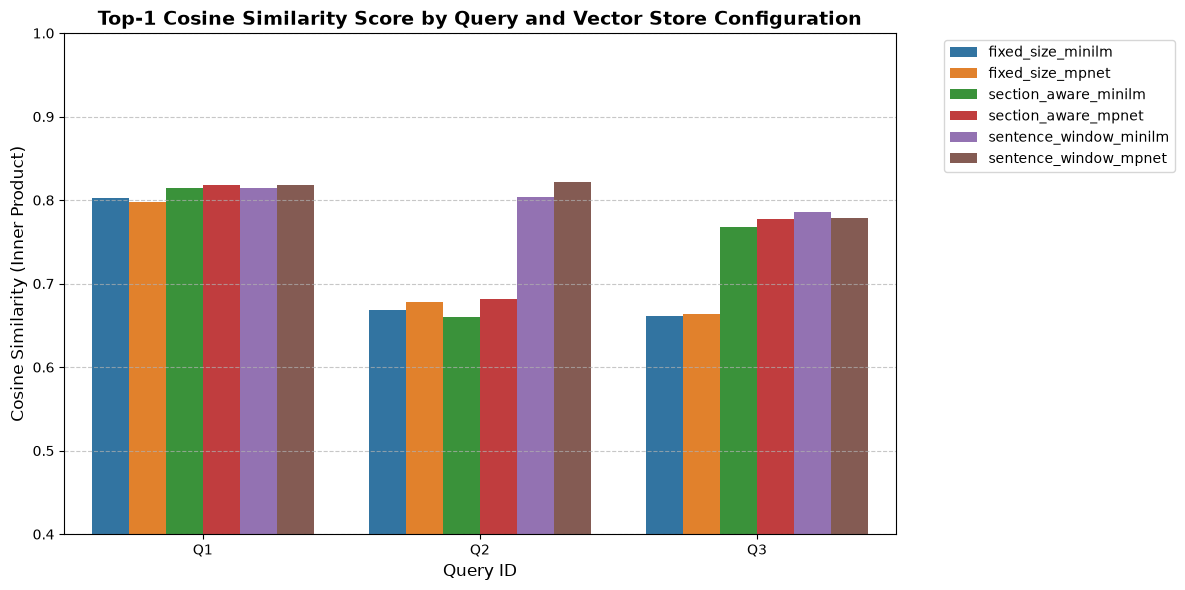

In [8]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=search_df,
    x="Query ID",
    y="Top-1 Score",
    hue="Index Key",
    palette="tab10"
)
plt.title("Top-1 Cosine Similarity Score by Query and Vector Store Configuration", fontsize=14, fontweight="bold")
plt.xlabel("Query ID", fontsize=12)
plt.ylabel("Cosine Similarity (Inner Product)", fontsize=12)
plt.ylim(0.4, 1.0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 10. Detailed Retrieval Inspection for Query 1
Let us inspect the top-3 retrieved chunks for Query 1 (*"How many consecutive sick leave days require a medical certificate?"*) on `section_aware_mpnet`:


In [9]:
q1_text = synthetic_queries[0]["question"]
q1_emb, _ = embed_texts([q1_text], model_mpnet, normalize=True)
q1_results = vector_stores["section_aware_mpnet"].search(q1_emb, k=3)

print(f"Query: '{q1_text}'\nIndex: section_aware_mpnet\n")
for res in q1_results:
    print(f"[Rank {res['rank']}] Score: {res['score']:.4f} | Chunk ID: {res['chunk_id']}")
    print(f"Policy: {res['metadata'].get('document_title')} | Section: {res['metadata'].get('section_heading')}")
    print(f"Excerpt: {res['metadata'].get('chunk_text')}")
    print("-" * 80)


Query: 'How many consecutive sick leave days require a medical certificate?'
Index: section_aware_mpnet

[Rank 1] Score: 0.8183 | Chunk ID: POL-SL-002_medical_documentation_secchk00
Policy: Sick Leave Policy | Section: Medical Documentation
Excerpt: A medical certificate from a registered medical practitioner is required for any sick leave absence exceeding 2 consecutive working days. The medical certificate must include the date of consultation, the recommended period of absence, and confirmation that the employee is unfit for work. Medical certificates must be submitted to the HR department within 3 working days of the employee's return to work.
--------------------------------------------------------------------------------
[Rank 2] Score: 0.7174 | Chunk ID: POL-SL-002_medical_documentation_secchk01
Policy: Sick Leave Policy | Section: Medical Documentation
Excerpt: The medical certificate must include the date of consultation, the recommended period of absence, and confirmation tha

## 11. Findings, Nuances, and Next Steps

### Key Technical Findings:
1. **Model Dimensionality & Throughput**:
   - `all-MiniLM-L6-v2` generates 384-dimensional embeddings at higher throughput with lower CPU memory footprint.
   - `all-mpnet-base-v2` generates 768-dimensional embeddings, taking more compute per chunk but capturing richer contextual semantics.
2. **FAISS Index FlatIP & L2-Normalization**:
   - Normalizing embeddings to unit length allows exact inner product retrieval (`IndexFlatIP`), providing true cosine similarities bounded between -1.0 and 1.0.
3. **Explicit Metadata Mapping**:
   - Because FAISS natively assigns sequential integer IDs (0 to N-1), our `FAISSVectorStore` explicitly tracks both chunk metadata and unique chunk IDs, preventing positional alignment bugs.

### Technical Nuance Regarding Performance:
> **Crucial Evaluation Principle**: A faster embedding generation speed does **NOT** indicate superior retrieval accuracy. Speed measures throughput, while retrieval quality requires systematic benchmark evaluation against a curated evaluation test set with ground-truth relevant chunks (which will be addressed in downstream evaluation stages).

### Next Steps:
- In Stage 6, we will integrate sparse lexical retrieval (BM25) and evaluate Hybrid Retrieval (combining dense FAISS semantic scores with BM25 keyword matching) to achieve balanced recall and precision.
